In [1]:
"""Demonstrate particle-resolved Brownian coagulation.

Generates a modest bimodal particle-resolved sample, configures Brownian
coagulation with ``distribution_type="particle_resolved"``, runs a short
step, and plots histograms of radii before/after execution to show how the
sample redistributes. Uses a small sample size to keep runtime fast.

Example:
    Run the script to visualize how Brownian coagulation redistributes a
    set of sampled radii in a particle-resolved representation via the
    public ``par.dynamics`` API.
"""

'Demonstrate particle-resolved Brownian coagulation.\n\nGenerates a modest bimodal particle-resolved sample, configures Brownian\ncoagulation with ``distribution_type="particle_resolved"``, runs a short\nstep, and plots histograms of radii before/after execution to show how the\nsample redistributes. Uses a small sample size to keep runtime fast.\n\nExample:\n    Run the script to visualize how Brownian coagulation redistributes a\n    set of sampled radii in a particle-resolved representation via the\n    public ``par.dynamics`` API.\n'

# Coagulation Pattern 3: Particle Resolved

Brownian coagulation using the public `par.dynamics` API with a
particle-resolved representation:

1. Build a Brownian coagulation strategy with
   `distribution_type="particle_resolved"`.
2. Wrap it in `par.dynamics.Coagulation`.
3. Run a short, fast step on a sampled aerosol and visualize the change.

In [2]:
# In Colab uncomment the following command to install particula:
# Use the v0.3.0 development checkout: `python -m pip install -e ".[extra]"`
import matplotlib.pyplot as plt
import numpy as np
import particula as par

## Build a particle-resolved aerosol

Sample a modest bimodal lognormal distribution, assign mass/density, and
combine with a simple atmosphere.

In [3]:
# Seed the illustrative sampling; this is not cross-backend replay.
np.random.seed(42)
# Sample radii (published 50,000-particle workload)
radii_sample = par.particles.get_lognormal_sample_distribution(
    mode=np.array([80e-9, 200e-9]),
    geometric_standard_deviation=np.array([1.4, 1.5]),
    number_of_particles=np.array([4e4, 2e4]),
    number_of_samples=50_000,
)

density = np.array([1_000.0])
mass_sample = 4 / 3 * np.pi * radii_sample**3 * density

# Native ambient environment. GasData requires a species axis, so a
# zero-concentration, non-partitioning carrier fills that axis. Coagulation
# does not consume it; ambient pressure is specified independently.
environment = par.gas.EnvironmentData(
    temperature=np.array([298.15]),
    pressure=np.array([101325.0]),
    saturation_ratio=np.zeros((1, 1)),
)
gas = par.gas.GasData(
    name=["carrier"],
    molar_mass=np.array([0.02897]),
    partitioning=np.array([False]),
    concentration=np.zeros((1, 1)),
)
# Unit count weights represent 50,000 particles in 1e-3 m³.
particles_resolved = par.particles.create_resolved_particle_data(
    masses=mass_sample,
    density=density,
    volume=1e-3,
)
aerosol_resolved = par.Aerosol(
    particles=particles_resolved,
    gas=gas,
    environment=environment,
)

## Configure coagulation (particle_resolved)

In [4]:
coagulation_strategy = (
    par.dynamics.BrownianCoagulationBuilder()
    .set_distribution_type("particle_resolved")
    .build()
)
coagulation_process = par.dynamics.Coagulation(
    coagulation_strategy=coagulation_strategy
)

print(coagulation_process)

## Execute a short coagulation step

In [5]:
time_step = 3600  # seconds (1 hour)
sub_steps = 20

radii_before = aerosol_resolved.particles.radii[0].copy()
initial_mass = np.sum(
    aerosol_resolved.particles.masses
    * aerosol_resolved.particles.concentration[..., None],
    axis=1,
)

aerosol_after = coagulation_process.execute(
    aerosol_resolved, time_step=time_step, sub_steps=sub_steps
)
radii_after = aerosol_after.particles.radii[0]
np.testing.assert_allclose(
    np.sum(
        aerosol_after.particles.masses
        * aerosol_after.particles.concentration[..., None],
        axis=1,
    ),
    initial_mass,
    rtol=1e-12,
    atol=1e-30,
)
assert np.all(aerosol_after.particles.masses >= 0)
assert np.sum(aerosol_after.particles.concentration) <= 50_000
# Free slots have radius zero; exclude them from the normalized active PDF.
radii_after = radii_after[aerosol_after.particles.concentration[0] > 0]

## Plot: particle-resolved histogram before/after

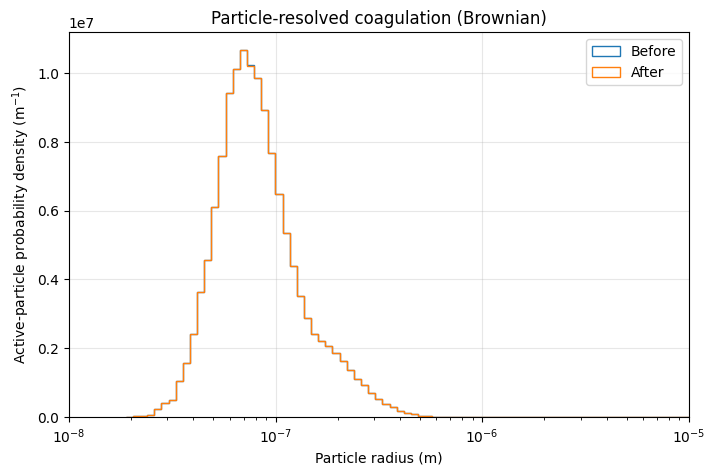

In [6]:
bins = np.logspace(np.log10(radii_before.min()), -5, 80).tolist()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    radii_before,
    bins=bins,
    histtype="step",
    color="tab:blue",
    label="Before",
    density=True,
)
ax.hist(
    radii_after,
    bins=bins,
    histtype="step",
    color="tab:orange",
    label="After",
    density=True,
)
ax.set_xscale("log")
ax.set_xlim(1e-8, 1e-5)
ax.set_xlabel("Particle radius (m)")
ax.set_ylabel("Active-particle probability density (m$^{-1}$)")
ax.set_title("Particle-resolved coagulation (Brownian)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Summary

- Strategy: `BrownianCoagulationBuilder().set_distribution_type("particle_resolved")`
- Runnable: `par.dynamics.Coagulation`
- Representation: particle-resolved sampled radii/mass
- Runtime guardrails: ~50k samples, 1-hour horizon, 20 sub-steps